# Problema 1 – Regressão Linear para Previsão de Produção de Energia em uma Usina de Ciclo Combinado


In [ ]:
import numpy as np
import io
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pd.set_option("display.max_columns", None)

# Dataset UCI CCPP — 9568 amostras
# O ZIP da UCI contém o arquivo Excel Folds5x2_pp.xlsx.
import requests

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00294/CCPP.zip"
response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    excel_files = [name for name in z.namelist() if name.lower().endswith(".xlsx")]
    print("Arquivos encontrados no ZIP:", excel_files)
    with z.open(excel_files[0]) as f:
        df = pd.read_excel(f)


df.columns = ["AT", "V", "AP", "RH", "PE"]
print("Dimensões:", df.shape)
display(df.head())
display(df.describe())

Arquivos encontrados no ZIP: ['CCPP/Folds5x2_pp.xlsx']
Dimensões: (9568, 5)


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


In [ ]:
scaler = StandardScaler()

df_scaled = df.copy()

df_scaled[["AT", "V", "AP", "RH"]] = scaler.fit_transform(
    df[["AT", "V", "AP", "RH"]]
)

print("Dados após padronização com StandardScaler (primeiras linhas):")
display(df_scaled.head())

X_cols = ["AT", "V", "AP", "RH"]

print("\nResumo estatístico após padronização (Média ~ 0 e Desvio Padrão ~ 1):")
display(df_scaled[X_cols].describe().round(4))

Dados após padronização com StandardScaler (primeiras linhas):


,AT,V,AP,RH,PE
0,-0.629519,-0.987297,1.820488,-0.009519,463.26
1,0.741909,0.681045,1.141863,-0.974621,444.37
2,-1.951297,-1.173018,-0.185078,1.289840,488.56
3,0.162205,0.237203,-0.508393,0.228160,446.48
4,-1.185069,-1.322539,-0.678470,1.596699,473.90



Resumo estatístico após padronização (Média ~ 0 e Desvio Padrão ~ 1):


,AT,V,AP,RH
count,9568.0000,9568.0000,9568.0000,9568.0000
mean,-0.0000,-0.0000,0.0000,-0.0000
std,1.0001,1.0001,1.0001,1.0001
min,-2.3941,-2.2779,-3.4300,-3.2706
25%,-0.8241,-0.9889,-0.7004,-0.6837
50%,0.0931,-0.1752,-0.0537,0.1141
75%,0.8144,0.9628,0.6737,0.7891
max,2.3428,2.1448,3.3748,1.8392


## 1. Correlação entre variáveis independentes e PE

A matriz de correlação permite verificar a associação linear entre AT, V, AP, RH e a variável-alvo PE. Quanto mais próximo de +1 ou -1, maior a associação linear.

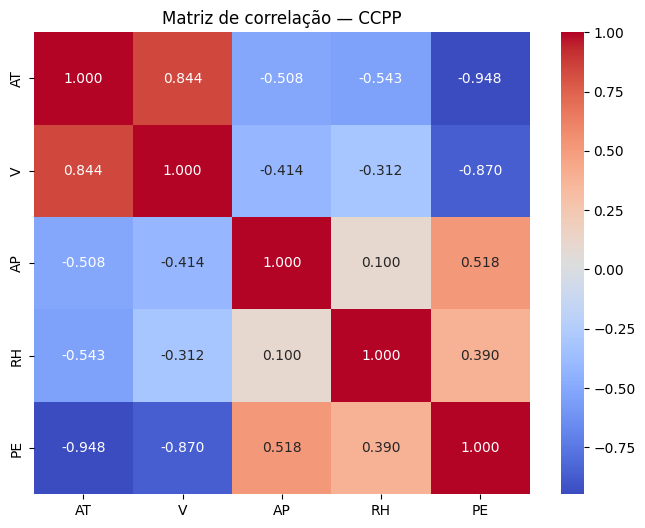

Correlação das variáveis independentes com PE:


,correlacao_com_PE
AT,-0.948128
V,-0.869780
AP,0.518429
RH,0.389794



Variável com maior correlação linear em valor absoluto: AT
Valor: -0.9481


In [ ]:
corr = df_scaled.corr(numeric_only=True)

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Matriz de correlação — CCPP")
plt.show()

corr_pe = corr["PE"].drop("PE").sort_values(key=abs, ascending=False)
print("Correlação das variáveis independentes com PE:")
display(corr_pe.to_frame("correlacao_com_PE"))

print("\nVariável com maior correlação linear em valor absoluto:", corr_pe.index[0])
print(f"Valor: {corr_pe.iloc[0]:.4f}")

## 2. Correlação entre as variáveis independentes

Correlação forte entre variáveis explicativas pode indicar **multicolinearidade**, o que dificulta interpretar separadamente os efeitos dos atributos em uma regressão linear.

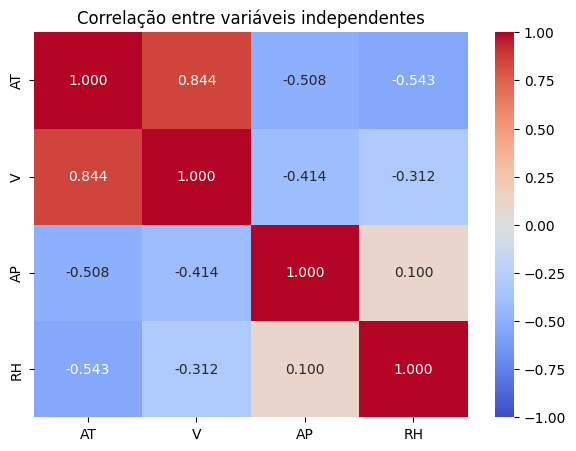

,Variavel_1,Variavel_2,correlacao,abs_correlacao
0,AT,V,0.844107,0.844107
2,AT,RH,-0.542535,0.542535
1,AT,AP,-0.507549,0.507549
3,V,AP,-0.413502,0.413502
4,V,RH,-0.312187,0.312187
5,AP,RH,0.099574,0.099574


In [ ]:
X_cols = ["AT", "V", "AP", "RH"]
corr_X = df_scaled[X_cols].corr(numeric_only=True)

plt.figure(figsize=(7,5))
sns.heatmap(corr_X, annot=True, cmap="coolwarm", fmt=".3f", vmin=-1, vmax=1)
plt.title("Correlação entre variáveis independentes")
plt.show()

# Pares com maior correlação absoluta
pairs = []
for i in range(len(X_cols)):
    for j in range(i+1, len(X_cols)):
        pairs.append((X_cols[i], X_cols[j], corr_X.loc[X_cols[i], X_cols[j]]))
pairs_df = pd.DataFrame(pairs, columns=["Variavel_1","Variavel_2","correlacao"])
pairs_df["abs_correlacao"] = pairs_df["correlacao"].abs()
display(pairs_df.sort_values("abs_correlacao", ascending=False))

## 3. Regressão Linear Múltipla

Será usado:
- 80% dos dados para treinamento;
- 20% para teste;
- imputação da mediana para valores ausentes;
- padronização das variáveis independentes;
- `LinearRegression` do scikit-learn.

A padronização é realizada dentro de um `Pipeline`, evitando vazamento de informação do conjunto de teste.

In [ ]:
X = df_scaled[X_cols]
y = df_scaled["PE"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Treino:", X_train.shape)
print("Teste :", X_test.shape)
print("Valores ausentes em X:", X.isna().sum().sum())
print("AT: ", X['AT'].isna().sum())
print("V: ", X['V'].isna().sum())
print("AP: ", X['AP'].isna().sum())
print("RH: ", X['RH'].isna().sum())

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

Treino: (7654, 4)
Teste : (1914, 4)
Valores ausentes em X: 0
AT:  0
V:  0
AP:  0
RH:  0


## 4. Avaliação: R², RMSE e MAE

,Metrica,Valor
0,R²,0.930105
1,RMSE,4.502633
2,MAE,3.595913


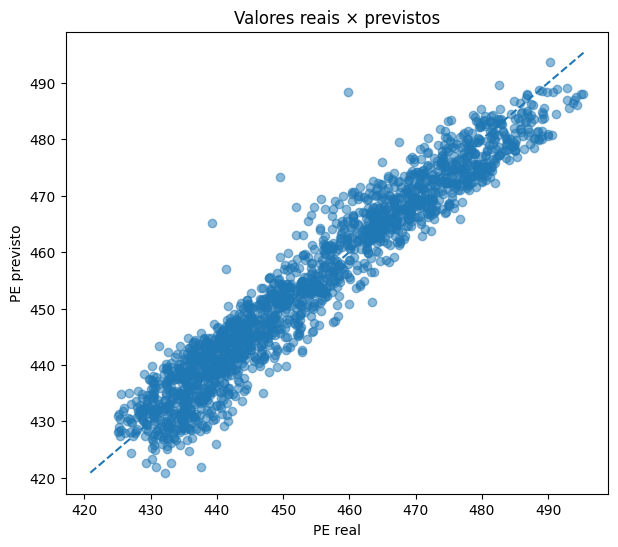

In [ ]:
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

resultados = pd.DataFrame({"Metrica": ["R²", "RMSE", "MAE"], "Valor": [r2, rmse, mae]})
display(resultados)

plt.figure(figsize=(7,6))
plt.scatter(y_test, y_pred, alpha=0.5)
limites = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(limites, limites, "--")
plt.xlabel("PE real")
plt.ylabel("PE previsto")
plt.title("Valores reais × previstos")
plt.show()
print()

## Conclusão automática

Use os valores calculados acima para justificar se o modelo é adequado. Em geral, **R² próximo de 1** indica que grande parte da variabilidade de PE é explicada pelo modelo, enquanto **RMSE e MAE menores** indicam menor erro de previsão. A conclusão final deve considerar simultaneamente as três métricas e o gráfico de resíduos.

In [ ]:
print(f"R² = {r2:.4f}")
print(f"RMSE = {rmse:.4f} MW")
print(f"MAE = {mae:.4f} MW")
print("\nInterpretação:")
if r2 >= 0.9:
    print("O modelo apresenta R² elevado, indicando forte capacidade de explicar a variação de PE.")
elif r2 >= 0.7:
    print("O modelo apresenta capacidade explicativa razoável/boa, mas ainda há variação não explicada.")
else:
    print("O modelo apresenta capacidade explicativa limitada e deve ser analisado com cautela.")
print("RMSE e MAE devem ser interpretados na unidade de PE (MW).")

R² = 0.9301
RMSE = 4.5026 MW
MAE = 3.5959 MW

Interpretação:
O modelo apresenta R² elevado, indicando forte capacidade de explicar a variação de PE.
RMSE e MAE devem ser interpretados na unidade de PE (MW).
